# Day 3 · Volume Trends & Application-Time Risk Drivers

*Work log: a cleaned version of my working notebook. The polished analysis lives in [`../01`–`05`](../).*

**Goals:** compare grade segments directly in SQL, diagnose the 2016 volume drop with a window function, and test home ownership and income as risk drivers.

**Key results:** after a one-off spike in March 2016, volume ran ~12% below its 2015 level for about a year. The −43% MoM drop in April is mostly a base effect. Income (19.6% → 10.3%) and home ownership (17.2% vs. 11.8%) carry signal but are much weaker than grade.

## 1. Setup

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = (Path.cwd().parents[1] / "Data").resolve()   # project_root/Data
con = duckdb.connect()

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

In [2]:
# Rebuild the analysis views (DuckDB views are in-memory and reset every session)

# loans: every accepted loan
con.sql(f"""
CREATE OR REPLACE VIEW loans AS
SELECT *
FROM '{DATA}/accepted.parquet'
""")

# loans_clean: drop the 33 file-footer rows and parse the text issue date ('Dec-2015') into a real date
con.sql("""
CREATE OR REPLACE VIEW loans_clean AS
SELECT *,
       strptime(issue_d, '%b-%Y') AS issue_date
FROM loans
WHERE loan_status IS NOT NULL
""")

# cohort: 36-month loans issued 2014-2015, all matured by Dec-2018 so outcomes are final
con.sql("""
CREATE OR REPLACE VIEW cohort AS
SELECT *
FROM loans_clean
WHERE issue_date BETWEEN '2014-01-01' AND '2015-12-31'
  AND TRIM(term) = '36 months'
""")

# rejected: declined applications
con.sql(f"""
CREATE OR REPLACE VIEW rejected AS
SELECT *
FROM '{DATA}/rejected.parquet'
""")

con.sql("SHOW TABLES").df()

,name
0,cohort
1,loans
2,loans_clean
3,rejected


## 2. Grade segments
Grouping grades in SQL avoids hand-averaging. Returns here are weighted by dollars, not loan counts.

In [3]:
con.sql("""
SELECT CASE
           WHEN grade = 'A'              THEN 'A'
           WHEN grade IN ('B', 'C')      THEN 'B-C'
           WHEN grade = 'D'              THEN 'D'
           WHEN grade IN ('E', 'F', 'G') THEN 'E-G'
       END AS grade_group,
       COUNT(*) AS n_loans,
       ROUND(AVG(CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
                        WHEN loan_status = 'Fully Paid' THEN 0 END), 4) AS bad_rate,
       ROUND(SUM(total_pymnt) * 1.0 / SUM(funded_amnt) - 1, 4) AS total_return
FROM cohort
GROUP BY grade_group
ORDER BY grade_group
""").df()

,grade_group,n_loans,bad_rate,total_return
0,A,105465,0.0542,0.0713
1,B-C,266742,0.1474,0.0799
2,D,53250,0.2467,0.0643
3,E-G,20286,0.3133,0.0441


E–G has **2.1×** the bad rate of B–C and earns only about **half** its return (B–C: 1.8×).

## 3. Monthly funded volume, 2015–2017
`DATE_TRUNC('month', …)` keeps the year. `MONTH()` alone would merge January 2015, 2016 and 2017.

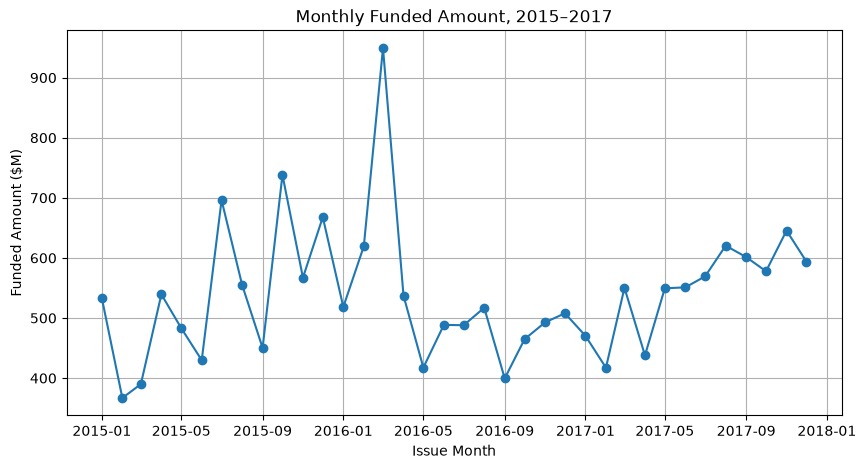

In [4]:
df = con.sql("""
SELECT DATE_TRUNC('month', issue_date)       AS issue_month,
       COUNT(*)                              AS n_loans,
       ROUND(SUM(funded_amnt) / 1000000, 1)  AS amount_mm
FROM loans_clean
WHERE issue_date >= '2015-01-01' AND issue_date < '2018-01-01'
GROUP BY issue_month
ORDER BY issue_month
""").df()

plt.figure(figsize=(10, 5))
plt.plot(df["issue_month"], df["amount_mm"], marker="o")
plt.title("Monthly Funded Amount, 2015–2017")
plt.xlabel("Issue Month")
plt.ylabel("Funded Amount ($M)")
plt.grid(True)
plt.show()

## 4. Month-over-month change with `LAG`

In [5]:
# LAG() pulls the previous month's value onto the current row; the 3 largest drops are shown
con.sql("""
WITH monthly AS (
    SELECT DATE_TRUNC('month', issue_date) AS issue_month,
           SUM(funded_amnt) / 1000000      AS amount_mm   -- keep full precision; round only for display
    FROM loans_clean
    WHERE issue_date >= '2015-01-01' AND issue_date < '2018-01-01'
    GROUP BY issue_month
)
SELECT issue_month,
       ROUND(amount_mm, 1)                                                   AS amount_mm,
       ROUND(LAG(amount_mm) OVER (ORDER BY issue_month), 1)                  AS prev_month_mm,
       ROUND(amount_mm / LAG(amount_mm) OVER (ORDER BY issue_month) - 1, 4)  AS mom_change
FROM monthly
ORDER BY mom_change
LIMIT 3
""").df()

,issue_month,amount_mm,prev_month_mm,mom_change
0,2016-04-01,537.3,949.4,-0.4341
1,2015-02-01,366.9,533.1,-0.3118
2,2015-11-01,567.2,738.2,-0.2316


**Findings**
* The largest drop, **April 2016 (−43.4%)**, follows an unusual spike in March 2016 (\$949M). Most of the drop is a **base effect**.
* Against a fairer baseline, the 2015 average of \$535M/month, volume ran at \$400–550M from May 2016 to April 2017 (about −12%) and recovered from May 2017.
* In 2015, peaks fall in quarter-start months (Apr, Jul, Oct). MoM comparisons are noisy, so year-over-year comparisons are needed.

**Investigation framework:** validate the data → add context (base effect, seasonality, baseline) → decompose (applications × approval rate × average loan size) → find the drivers (internal policy vs. external factors).

## 5. Risk driver: home ownership

In [6]:
# SUM(COUNT(*)) OVER () = total across all groups -> share of loans per group
con.sql("""
SELECT home_ownership,
       COUNT(*) AS n_loans,
       ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4) AS pct_loans,
       ROUND(AVG(CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
                        WHEN loan_status = 'Fully Paid' THEN 0 END), 4) AS bad_rate
FROM cohort
GROUP BY home_ownership
ORDER BY bad_rate DESC
""").df()

,home_ownership,n_loans,pct_loans,bad_rate
0,RENT,191283,0.4291,0.1718
1,OWN,48309,0.1084,0.1536
2,MORTGAGE,206149,0.4625,0.1176
3,ANY,2,0.0000,0.0000


* Renters are the riskiest (17.2%). Mortgage holders are the safest (11.8%), and they are even safer than outright owners (15.4%), possibly because they already passed a bank's underwriting.
* `ANY` has only 2 loans, too few to draw conclusions. Sample size should be judged by absolute counts, not by share.

## 6. Risk driver: income bands (binning)

In [7]:
# Rules: every loan lands in exactly one bin; missing values get their own bin;
# numeric prefixes keep the labels in the right sort order
income = con.sql("""
SELECT CASE
           WHEN annual_inc IS NULL  THEN '0. Missing'
           WHEN annual_inc < 40000  THEN '1. <40k'
           WHEN annual_inc < 60000  THEN '2. 40-60k'
           WHEN annual_inc < 80000  THEN '3. 60-80k'
           WHEN annual_inc < 100000 THEN '4. 80-100k'
           ELSE                          '5. 100k+'
       END AS income_band,
       COUNT(*) AS n_loans,
       ROUND(AVG(CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
                        WHEN loan_status = 'Fully Paid' THEN 0 END), 4) AS bad_rate
FROM cohort
GROUP BY income_band
ORDER BY income_band
""").df()

# Sanity check: the bins must add up to the full cohort
print("total loans in bins:", income["n_loans"].sum())
income

total loans in bins: 445743


,income_band,n_loans,bad_rate
0,1. <40k,83107,0.1961
1,2. 40-60k,120993,0.1561
2,3. 60-80k,96892,0.1382
3,4. 80-100k,58956,0.1201
4,5. 100k+,85795,0.1033


**Bug found and fixed:** my first version used `annual_inc > 100000` for the top bin, which left **8,430 loans** reporting exactly \$100,000 with no bin (NULL). Lower bounds are now inclusive, and the bin totals add up to 445,743.

**Findings**
* The bad rate falls **monotonically** from 19.6% to 10.3% as income rises. Monotonic risk is required for scorecard bins.
* The biggest step is from <\$40k to \$40–60k (−4.0 pp). After that, each band drops about 1.8 pp, which is still a 13–15% *relative* reduction.
* Spread: income 1.9×, home ownership 1.5×, grade 7.8×. These variables help, but a multivariate model is needed.